#**Take Home Test - Uber Eats Delivery**

Merupakan tahapan dari rangkaian coding test dalam proses penyaluran kerja dari program Bootcamp Data Analyst & Business Intelligence (DABI) - Dibimbing ID. Present on class using English.

 Bootcamp DABI 23 - Adika Rizqi Irfanto

 Dataset: https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction?resource=download$0

## Preparing Dataset

In [ ]:
# preparing dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# importing dataset
df = pd.read_csv("/content/Food_Delivery_Times.csv")
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


### Business Question
1. Bagaimana performa pengantaran Uber Food dilihat dari data yang dimiliki?
2. Apa saja faktor yang memiliki pengaruh besar terhadap waktu tempuh pengantaran yang dihasilkan?
3. Bagaimana upaya evaluasi dan pengembangan lebih lanjut untuk mengoptimalkan kondisi dari faktor tersebut?

## Data Cleaning

In [ ]:
# dataset overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [ ]:
# cek duplikasi
df.duplicated().sum()

np.int64(0)

In [ ]:
# cek null atau missing values
df.isna().sum() / df.shape[0] * 100

,0
Order_ID,0.0
Distance_km,0.0
Weather,3.0
Traffic_Level,3.0
Time_of_Day,3.0
Vehicle_Type,0.0
Preparation_Time_min,0.0
Courier_Experience_yrs,3.0
Delivery_Time_min,0.0


In [ ]:
# statistika deskriptif
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [ ]:
# cek baris missing values
cols = ["Weather", "Traffic_Level", "Time_of_Day", "Courier_Experience_yrs"]

print(df[cols].isnull().any(axis=1).sum())
print(df[cols].isnull().all(axis=1).sum())

117
0


Temuan utama:
1. Missing value yang ada pada dataset tidak berasal dari row data yang sama.
2. Penting dilakukan analisis sebelum melakukan handling, sehingga dapat dipertimbangkan untuk dilakukan imputasi dengan nilai median untuk data numerik dan modus untuk data kategori.

Berdasarkan temuan yang ada, sebetulnya karena null atau missing values yang ada memiliki presentase yang kecil terhadap keseluruhan dataset maka boleh saja untuk di drop.

Namun, disini akan dilakukan imputasi saja menggunakan median untuk data numerik dan modus untuk data kategori.

In [ ]:
# handle null
df["Weather"].fillna(df["Weather"].mode()[0], inplace=True)
df["Traffic_Level"].fillna(df["Traffic_Level"].mode()[0], inplace=True)
df["Time_of_Day"].fillna(df["Time_of_Day"].mode()[0], inplace=True)
df["Courier_Experience_yrs"].fillna(df["Courier_Experience_yrs"].median(), inplace=True)

In [ ]:
# validasi hasil
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 1000 non-null   object 
 3   Traffic_Level           1000 non-null   object 
 4   Time_of_Day             1000 non-null   object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  1000 non-null   float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


## Data Manipulation

In [ ]:
# penyesuaian tipe data
df["Order_ID"] = df["Order_ID"].astype("object")
df["Preparation_Time_min"] = df["Preparation_Time_min"].astype("float64")

In [ ]:
df["Distance_km"].unique()

array([ 7.93, 16.42,  9.52,  7.44, 19.03, 19.4 , 17.39,  1.78, 10.62,
       16.86, 15.54, 10.89,  4.69,  2.8 ,  2.17, 17.86,  2.53,  6.58,
        5.38, 15.56, 13.08,  0.86,  5.83, 11.2 , 14.59, 12.91, 13.92,
        4.04, 18.05, 12.88, 19.45,  4.58, 19.73,  2.47, 17.8 ,  5.96,
       12.85,  1.02,  6.84,  8.68, 10.69,  0.99,  1.11,  2.16, 13.17,
        8.79,  5.93,  2.09,  7.57, 10.52,  4.83, 19.81, 10.1 ,  7.64,
       12.35,  5.9 ,  0.9 , 11.58, 16.16, 15.51, 12.16,  4.96,  3.64,
        2.85, 10.4 , 12.31,  3.53, 13.6 , 15.23,  4.17,  3.21,  6.38,
       16.54, 12.02, 11.94,  9.08,  3.46,  6.8 , 17.38,  3.25, 10.28,
       16.14,  3.55, 10.65,  7.3 ,  7.03, 12.43, 12.76, 11.39, 19.41,
        8.32,  1.92,  1.15,  7.46,  7.25, 16.7 , 17.2 , 18.76,  9.22,
        2.84, 17.59, 14.89,  1.3 , 18.99,  1.6 ,  8.26, 10.16, 12.03,
       14.73, 12.56,  5.53, 10.18, 15.5 ,  2.98, 16.69, 11.22,  8.53,
       12.49,  0.97, 12.6 ,  6.91, 18.97,  4.05, 14.29, 12.11, 14.94,
        2.29, 17.36,

In [ ]:
# feature engineering: segmentasi jarak
def categorize_distance(distance):
    if distance <= 5:
        return "Low Distance"
    elif distance <= 10:
        return "Medium Distance"
    elif distance <= 15:
        return "High Distance"
    else:
        return "Very High Distance"

df["Distance_Group"] = df["Distance_km"].apply(
    categorize_distance
)

In [ ]:
df["Delivery_Time_min"].unique()

array([ 43,  84,  59,  37,  68,  57,  49,  46,  35,  73,  88,  76,  53,
        36,  33,  50,  24,  27,  47,  72,  58,  56,  64,  70, 123,  52,
       108,  45, 111,  44,  61,  34,  67,  32,   8, 104,  31,  23,  82,
        69,  60,  40,  38,  54,  87,  62,  22,  42,  51,  41,  48,  92,
        71,  65,  28,  74,  14,  30,  94,  80,  91,  79,  77,  26, 141,
        78,  29, 105,  16, 116,  75,  25, 113,  17,  66,  85, 100,  21,
        89,  55,  96,  13,  90, 112,  63,  39, 101,  93,  83, 109,  20,
        19, 153, 102, 103,  86, 115,  15,  98, 106,  97,  18,  99,  81,
        95, 126, 122, 114])

In [ ]:
# feature engineering: segmentasi waktu antar
def categorize_time(time):
    if time <= 15:
        return "Early Time"
    elif time <= 30:
        return "Mid Time"
    elif time <= 45:
        return "Late Time"
    else:
        return "Very Late Time"

df["Time_Group"] = df["Delivery_Time_min"].apply(
    categorize_time
)

In [ ]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Distance_Group,Time_Group
0,522,7.93,Windy,Low,Afternoon,Scooter,12.0,1.0,43,Medium Distance,Late Time
1,738,16.42,Clear,Medium,Evening,Bike,20.0,2.0,84,Very High Distance,Very Late Time
2,741,9.52,Foggy,Low,Night,Scooter,28.0,1.0,59,Medium Distance,Very Late Time
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5.0,1.0,37,Medium Distance,Late Time
4,412,19.03,Clear,Low,Morning,Bike,16.0,5.0,68,Very High Distance,Very Late Time


## EDA: Feature Correlation

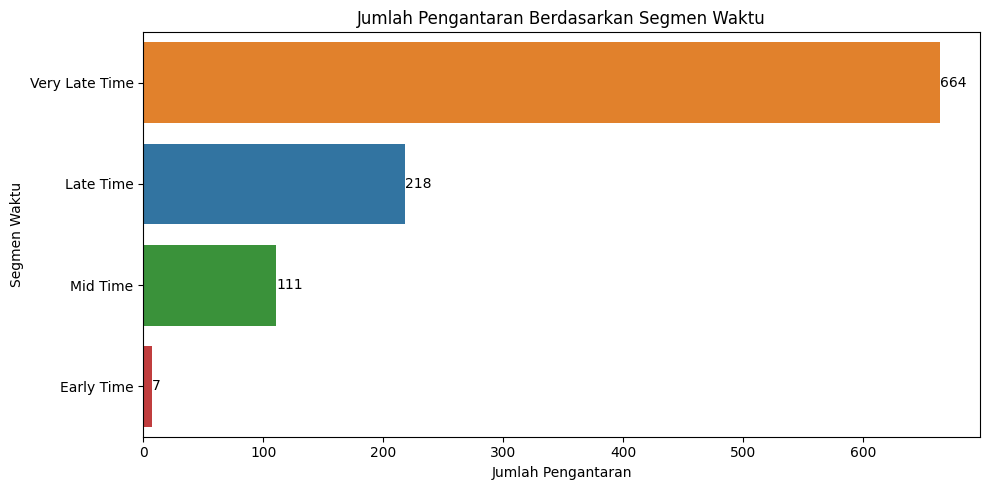

In [ ]:
# performa pengantaran
plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df,
    y="Time_Group",
    hue="Time_Group",
    order=df["Time_Group"].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Jumlah Pengantaran Berdasarkan Segmen Waktu")
plt.xlabel("Jumlah Pengantaran")
plt.ylabel("Segmen Waktu")

plt.tight_layout()
plt.show()

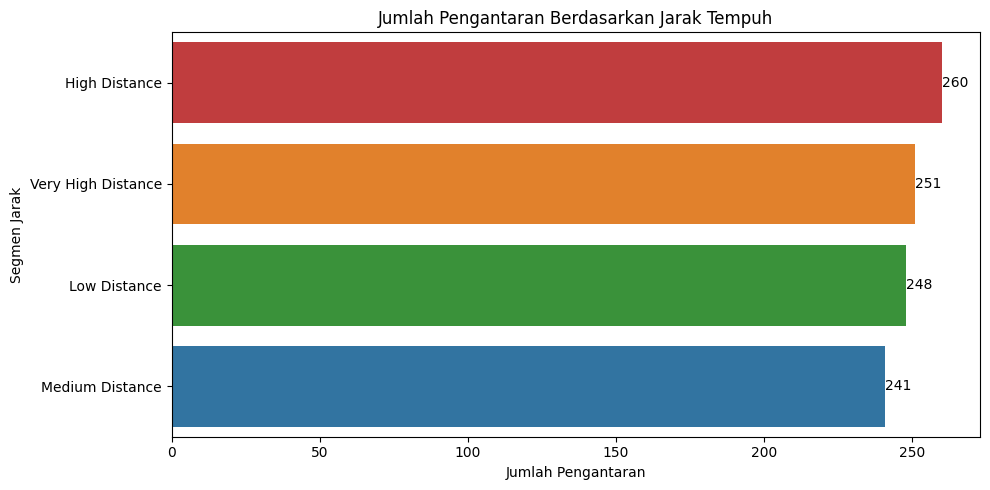

In [ ]:
# karakteristik pengantaran
plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df,
    y="Distance_Group",
    hue="Distance_Group",
    order=df["Distance_Group"].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Jumlah Pengantaran Berdasarkan Jarak Tempuh")
plt.xlabel("Jumlah Pengantaran")
plt.ylabel("Segmen Jarak")

plt.tight_layout()
plt.show()

### BQ1: Performa Pengiriman Uber
Berdasarkan analisis berupa EDA sederhana, diketahui bahwa histori pengiriman yang telah dilakukan didominasi oleh keterlambatan yang sangat tinggi meskipun memiliki persebaran karakteristik tujuan pengantaran yang beragam, mulai dari dekat hingga sangat jauh.

Analisis lanjutan diperlukan untuk mengidentifikasi karakteristik yang berkaitan dengan durasi pengantaran serta menentukan area yang perlu dioptimalkan. Oleh karena itu, penting untuk diuji variabel manakah yang paling berpengaruh terhadap durasi pengiriman.

Dalam melakukan uji korelasi antar variabel, penting untuk diketahui terlebih dahulu mengenai kondisi distribusi data yang dimiliki oleh suatu variabel. Analisis distribusi dapat dilakukan melalui:
1. Data Numerik: melakukan analisis statistika sederhana baik secara teknis maupun visualisasi histoplot.
2. Data Kategori: melakukan analisis statistika sederhana melalui tahapan encoding.

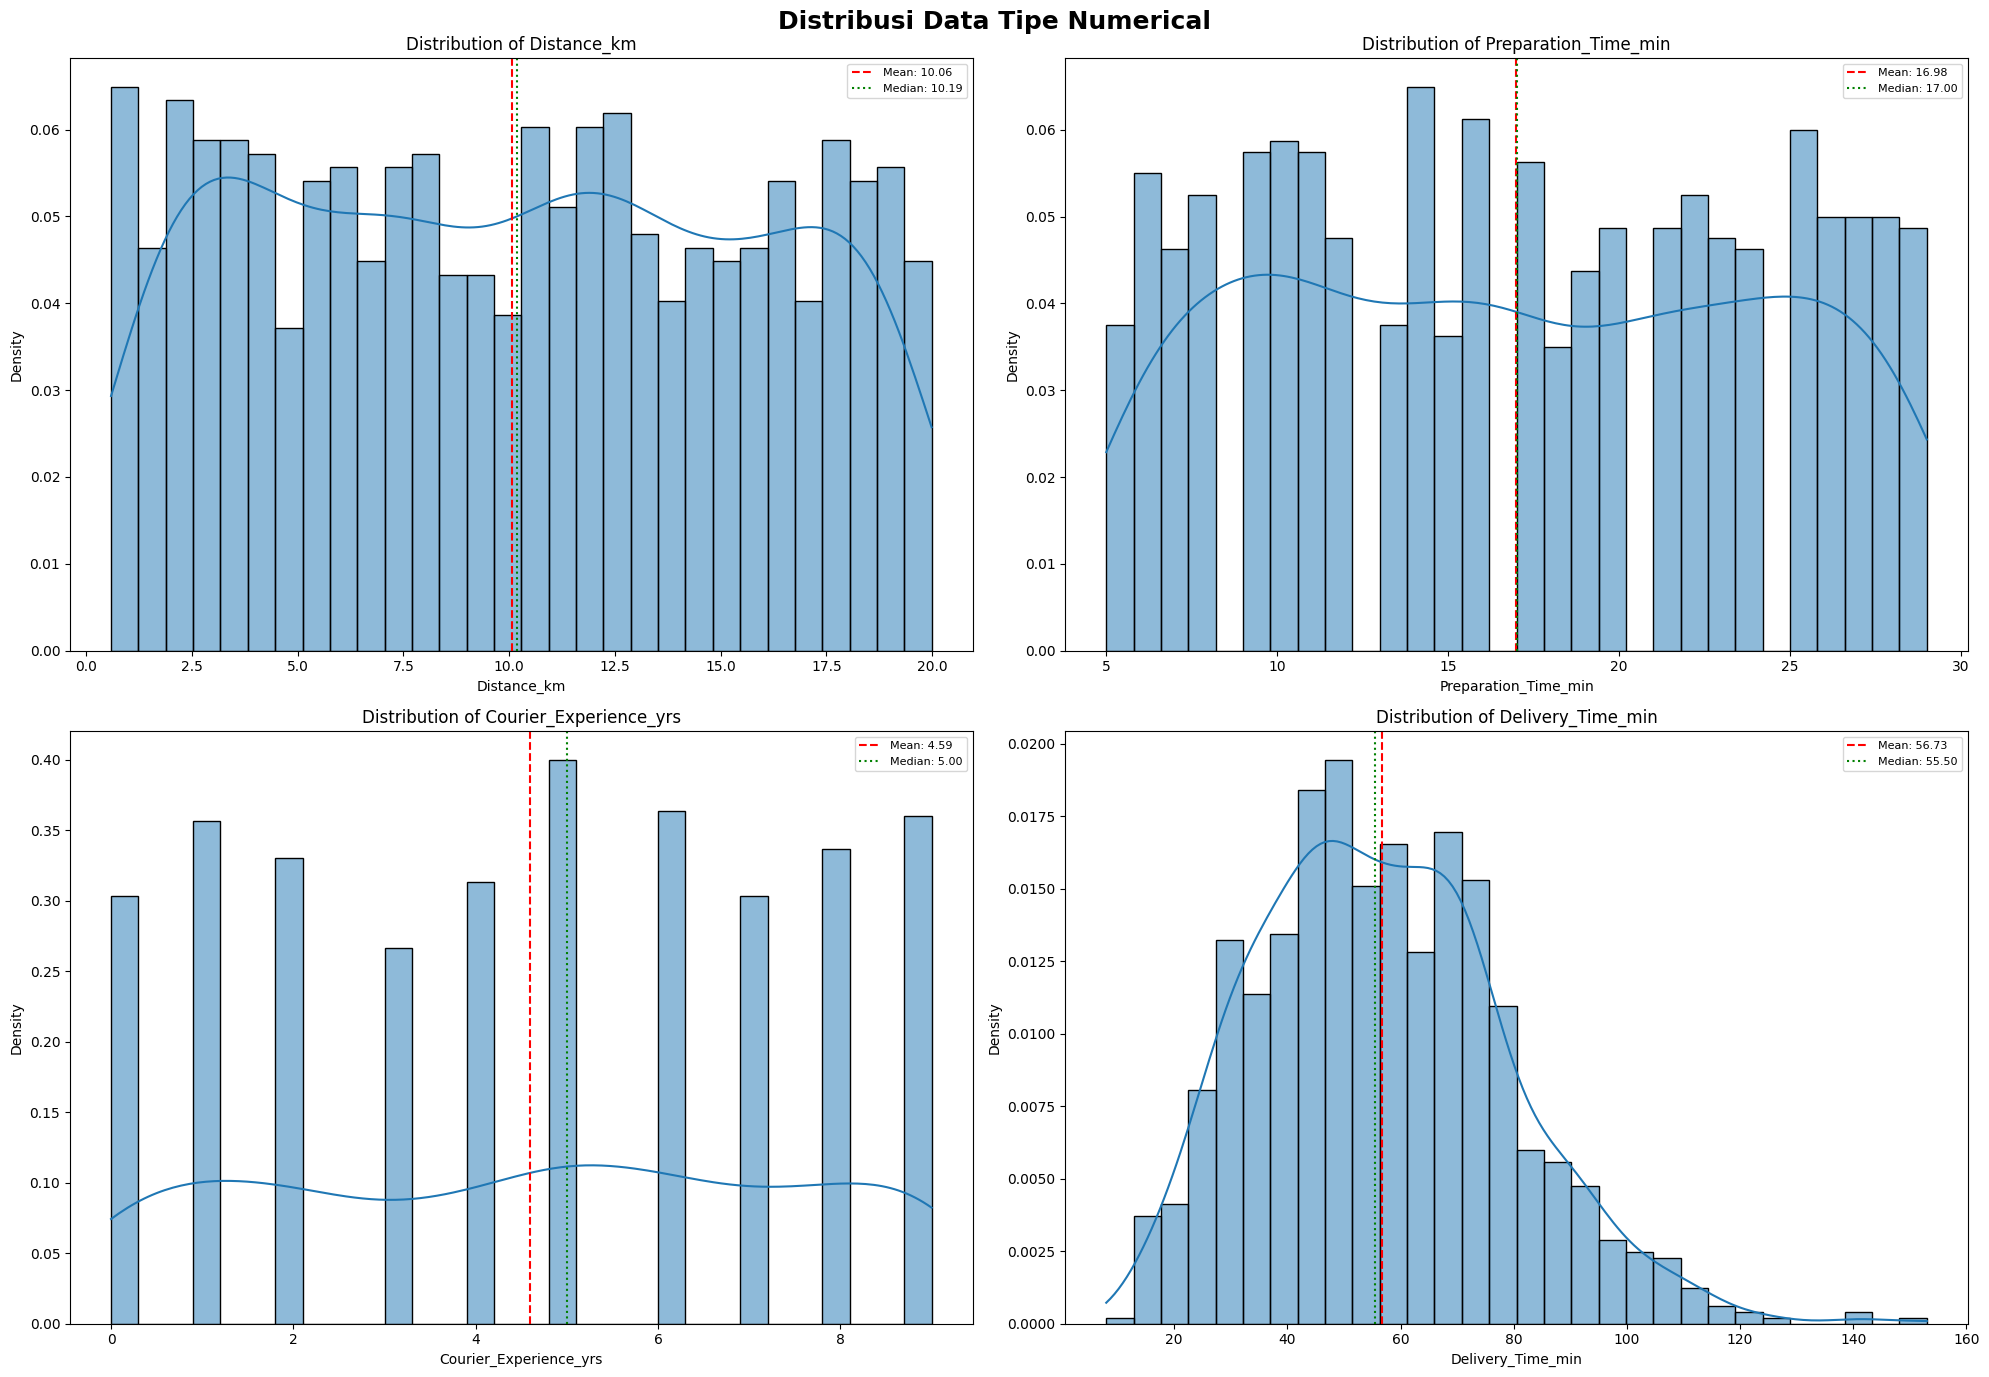

In [ ]:
# distribusi data
import math

numeric_cols = df.select_dtypes(
    include="number"
).columns.tolist()

n_cols = 2
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, 7 * n_rows)
)

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(numeric_cols):
    ax = axes[i]

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        stat="density",
        ax=ax
    )

    mean_val = df[col].mean()
    median_val = df[col].median()

    ax.axvline(
        mean_val,
        color="red",
        linestyle="--",
        label=f"Mean: {mean_val:.2f}"
    )

    ax.axvline(
        median_val,
        color="green",
        linestyle=":",
        label=f"Median: {median_val:.2f}"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Distribusi Data Tipe Numerical",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

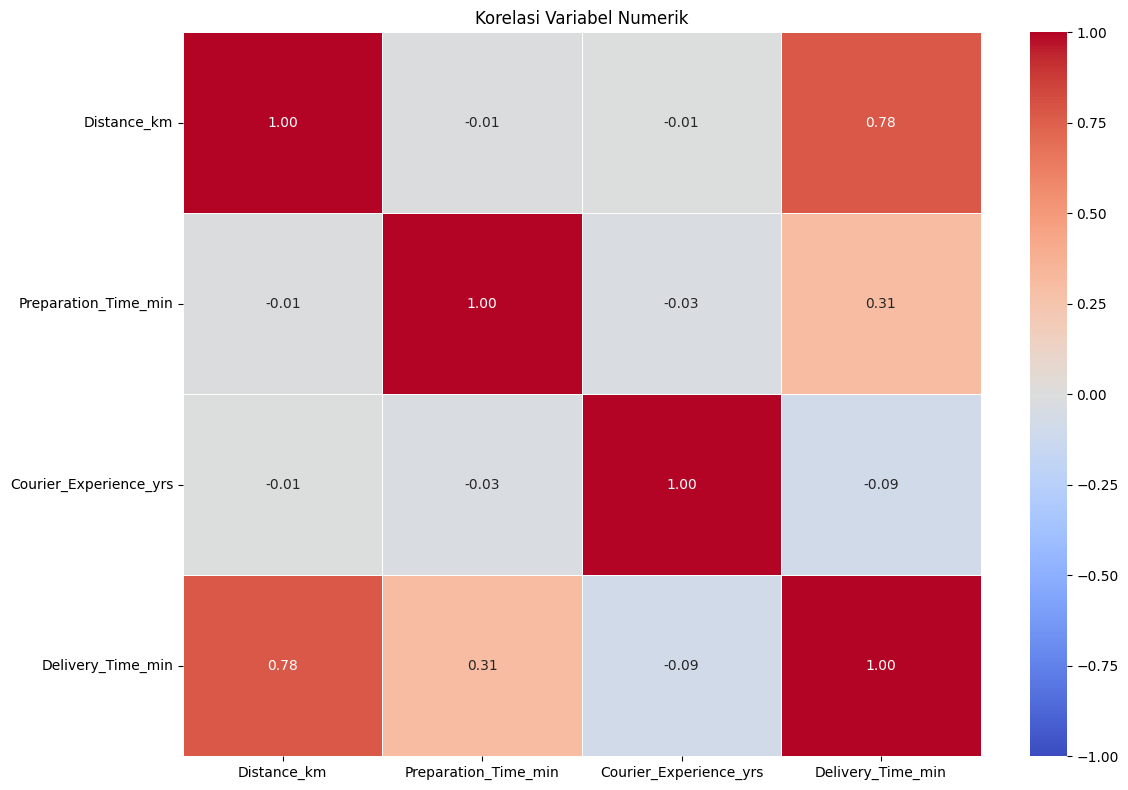

In [ ]:
# korelasi seluruh variabel numerik
# distribusi normal, default

corr_matrix = df.select_dtypes(
    include="number"
).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

In [ ]:
# one hot encoding untuk data kategori
df_cat = pd.get_dummies(
    df,
    columns=[
        "Weather",
        "Traffic_Level",
        "Time_of_Day",
        "Vehicle_Type"
    ],
    dtype=int
)

df_cat.head()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Distance_Group,Time_Group,Weather_Clear,Weather_Foggy,Weather_Rainy,...,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium,Time_of_Day_Afternoon,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Bike,Vehicle_Type_Car,Vehicle_Type_Scooter
0,522,7.93,12.0,1.0,43,Medium Distance,Late Time,0,0,0,...,0,1,0,1,0,0,0,0,0,1
1,738,16.42,20.0,2.0,84,Very High Distance,Very Late Time,1,0,0,...,0,0,1,0,1,0,0,1,0,0
2,741,9.52,28.0,1.0,59,Medium Distance,Very Late Time,0,1,0,...,0,1,0,0,0,0,1,0,0,1
3,661,7.44,5.0,1.0,37,Medium Distance,Late Time,0,0,1,...,0,0,1,1,0,0,0,0,0,1
4,412,19.03,16.0,5.0,68,Very High Distance,Very Late Time,1,0,0,...,0,1,0,0,0,1,0,1,0,0


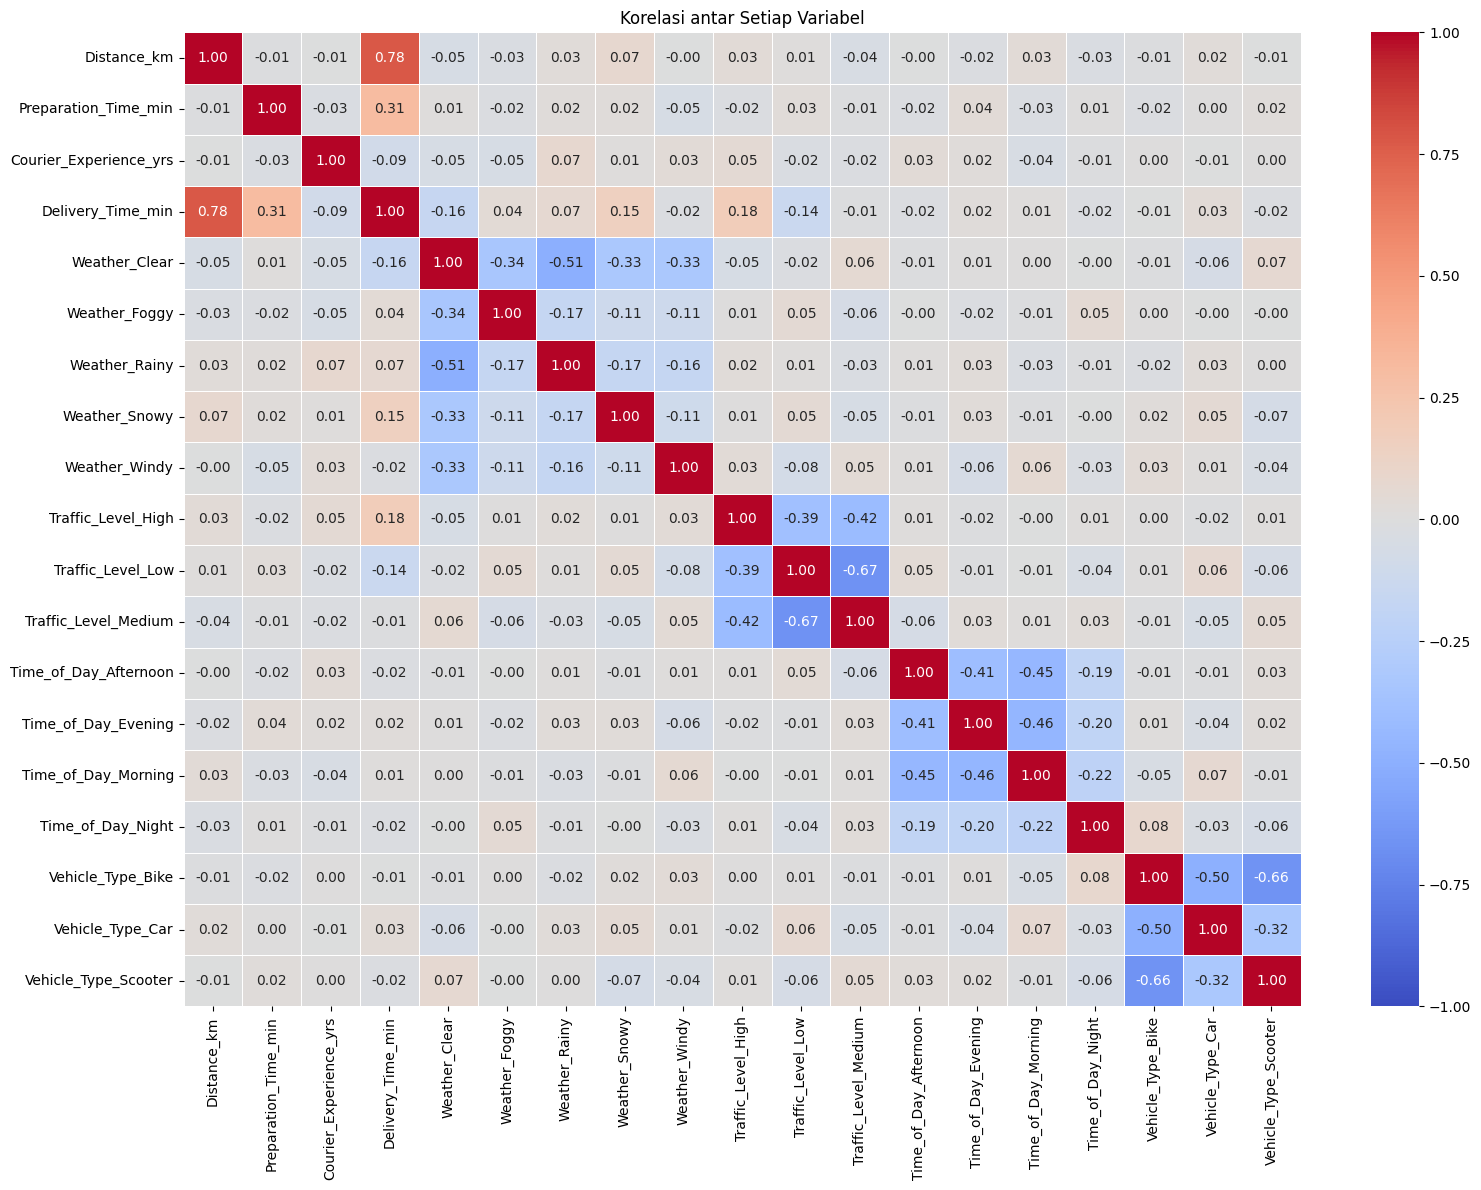

In [ ]:
# korelasi include hasil encoding
corr_data = df_cat.select_dtypes(include="number").drop(
    columns=["Order_ID"], errors="ignore"
)
corr_matrix = corr_data.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Korelasi antar Setiap Variabel")
plt.tight_layout()
plt.show()

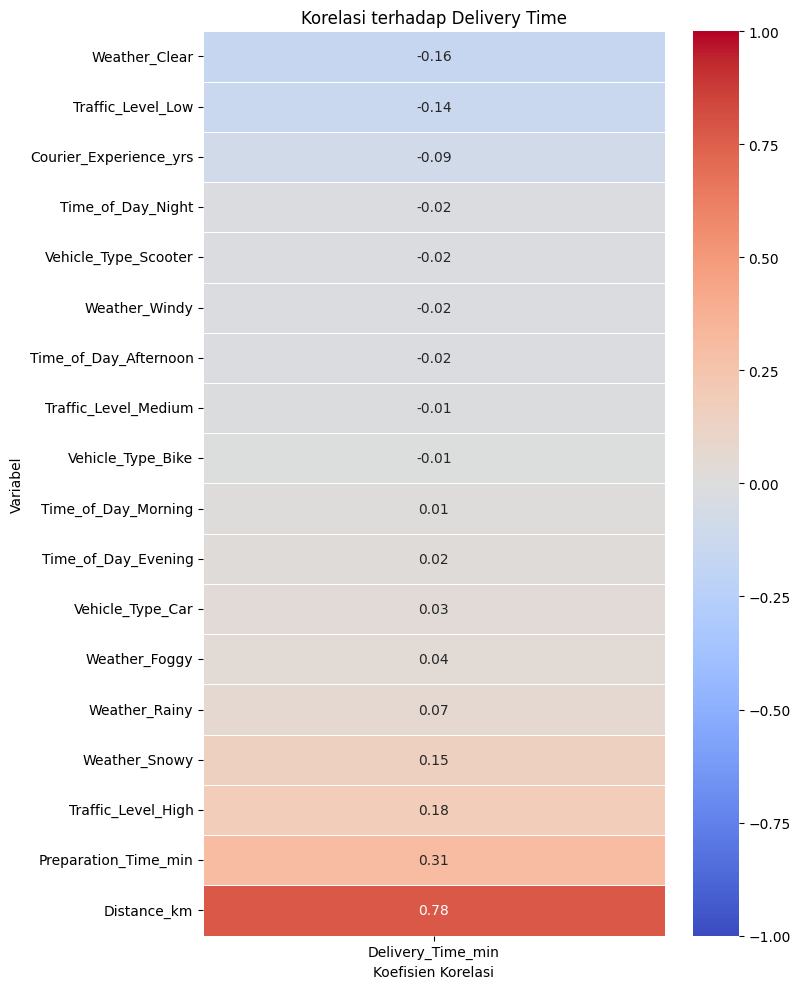

In [ ]:
# berfokus terhadap waktu pengiriman
target = "Delivery_Time_min"

target_corr = (
    corr_data.corr()[target]
    .drop(target)
    .sort_values()
)

plt.figure(figsize=(8, 10))
sns.heatmap(
    target_corr.to_frame(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Korelasi terhadap Delivery Time")
plt.ylabel("Variabel")
plt.xlabel("Koefisien Korelasi")
plt.tight_layout()
plt.show()

### BQ2: Nilai Hasil Korelasi
Hasil secara Umum

Berdasarkan hasil uji korelasi keseluruhan yang telah dilakukan, dapat diketahui bahwa variabel yang menjadi target utama adalah variabel "Delivery_Time_min". Adapun korelasi antar variabel lainnya didominasi nilai koefisien korelasi yang mendekati 0, baik positif maupun negatif, sehingga hanya dapat diasumsikan hubungannya sangat lemah antar satu sama lain.

Fokus terhadap Durasi Pengiriman
Berdasarkan uji korelasi yang dilakukan, diketahui bahwa faktor yang paling berpengaruh terhadap waktu pengiriman adalah:
1. Variabel "Distance_km" memiliki koefisien korelasi sebesar 0.78 dengan arah yang sejajar atau positif.
2. Variabel "Preparation_Time_min" memiliki koefisien korelasi sebesar 0.31 dengan arah yang sejajar atau positif.
3. Variabel "Traffic_High_Level" dan "Weather_Snowy" memiliki koefisien korelasi 0.18 dan 0.15 dengan arah yang sejajar atau positif.

Jika mengacu pada threshold yang berlaku maka variabel 1 memiliki hubungan yang kuat, variabel 2 memiliki hubungan yang lemah, serta variabel 3 dan 4 memiliki hubungan yang sangat lemah terhadap durasi waktu pengantaran. Namun, penting diingat bahwa korelasi hanya menunjukkan tingkat kekuatan hubungan antar variabel, bukan menjadi satu satunya faktor penentu dari suatu variabel yang diuji.

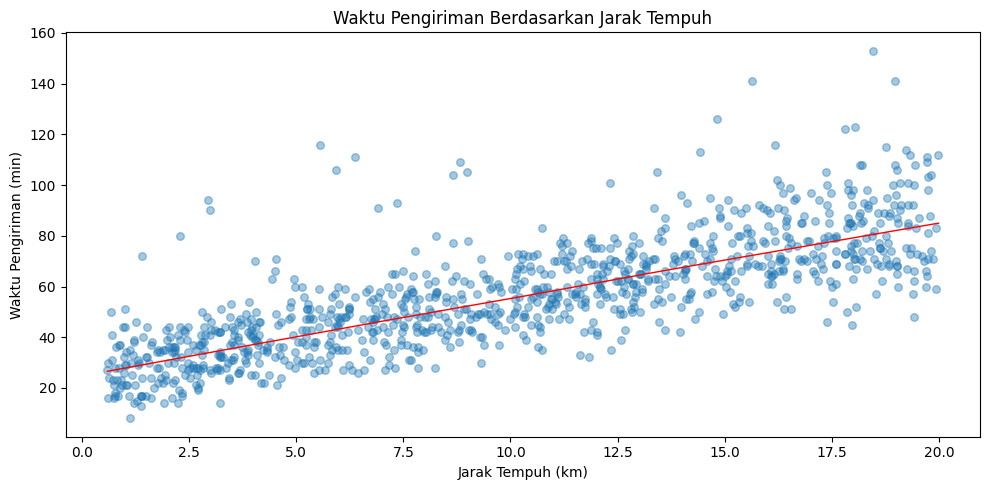

In [ ]:
# visual waktu pengiriman terhadap jarak yang ditempuh
plt.figure(figsize=(10, 5))
ax = sns.regplot(
    data=df,
    x="Distance_km",
    y="Delivery_Time_min",
    lowess=True,
    scatter_kws={"alpha": 0.4, "s": 30},
    line_kws={"color": "red", "linewidth": 1}
)

plt.title("Waktu Pengiriman Berdasarkan Jarak Tempuh")
plt.xlabel("Jarak Tempuh (km)")
plt.ylabel("Waktu Pengiriman (min)")

plt.tight_layout()
plt.show()

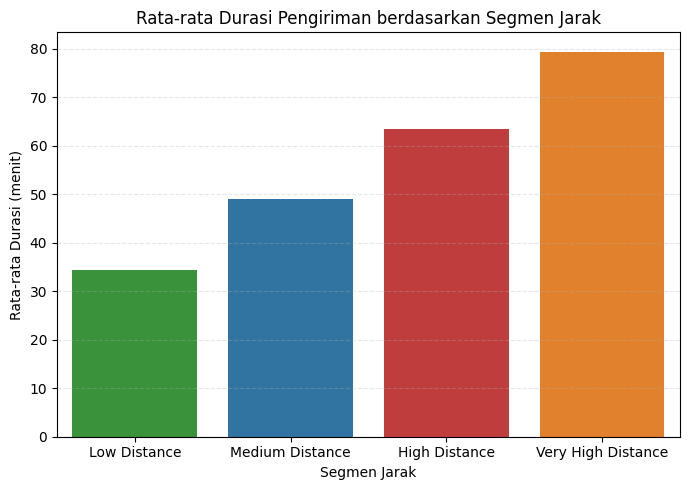

In [ ]:
# gambaran persebarannya
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Distance_Group",
    y="Delivery_Time_min",
    estimator="mean",
    hue="Distance_Group",
    errorbar=None,
    order=["Low Distance",
           "Medium Distance",
           "High Distance",
           "Very High Distance"]
)

plt.title("Rata-rata Durasi Pengiriman berdasarkan Segmen Jarak")
plt.xlabel("Segmen Jarak")
plt.ylabel("Rata-rata Durasi (menit)")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### BQ3: Rekomendasi Optimasi
Berdasarkan temuan yang diperoleh, dapat ditentukan sejumlah rekomendasi strategis sebagai berikut:
1. Mengoptimalkan sistem dalam penentuan driver Ubers terdekat terhadap lokasi pengambilan pesanan dan waktu persiapannya sehingga durasi pengiriman dapat lebih ditekan kembali.
2. Melakukan mitigasi terhadap tingkat kemacetan dengan menganalisis pattern kesibukan sosial pada posisi waktu yang kritis.
3. Melakukan mitigasi dalam menghadapi musim dingin "Weather_Snowy" dengan memberikan strategi operasional pendukung bagi driver Ubers dalam pengiriman pada kondisi tertentu yang terjadi.

## Dataset for Visualization

Berdasarkan hasil analisis yang telah dilakukan maka dapat dilakukan export data untuk kemudian divisualisasikan melalui platform seperti Power BI ataupun Tableau.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   object 
 1   Distance_km             1000 non-null   float64
 2   Weather                 1000 non-null   object 
 3   Traffic_Level           1000 non-null   object 
 4   Time_of_Day             1000 non-null   object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   float64
 7   Courier_Experience_yrs  1000 non-null   float64
 8   Delivery_Time_min       1000 non-null   int64  
 9   Distance_Group          1000 non-null   object 
 10  Time_Group              1000 non-null   object 
dtypes: float64(3), int64(1), object(7)
memory usage: 86.1+ KB


In [ ]:
df_cat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   object 
 1   Distance_km             1000 non-null   float64
 2   Preparation_Time_min    1000 non-null   float64
 3   Courier_Experience_yrs  1000 non-null   float64
 4   Delivery_Time_min       1000 non-null   int64  
 5   Distance_Group          1000 non-null   object 
 6   Time_Group              1000 non-null   object 
 7   Weather_Clear           1000 non-null   int64  
 8   Weather_Foggy           1000 non-null   int64  
 9   Weather_Rainy           1000 non-null   int64  
 10  Weather_Snowy           1000 non-null   int64  
 11  Weather_Windy           1000 non-null   int64  
 12  Traffic_Level_High      1000 non-null   int64  
 13  Traffic_Level_Low       1000 non-null   int64  
 14  Traffic_Level_Medium    1000 non-null   i

In [ ]:
# saving sebagai csv untuk visualisasi
df.to_csv("Food_Delivery_Times_2.0.csv", index=False)
df_cat.to_csv("Food_Delivery_Times_3.0.csv", index=False)

In [ ]:
# cek dataset untuk visualisasi
data = pd.read_csv("/content/Food_Delivery_Times_2.0.csv")
data.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Distance_Group,Time_Group
0,522,7.93,Windy,Low,Afternoon,Scooter,12.0,1.0,43,Medium Distance,Late Time
1,738,16.42,Clear,Medium,Evening,Bike,20.0,2.0,84,Very High Distance,Very Late Time
2,741,9.52,Foggy,Low,Night,Scooter,28.0,1.0,59,Medium Distance,Very Late Time
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5.0,1.0,37,Medium Distance,Late Time
4,412,19.03,Clear,Low,Morning,Bike,16.0,5.0,68,Very High Distance,Very Late Time


In [ ]:
dataa = pd.read_csv("/content/Food_Delivery_Times_3.0.csv")
dataa.head()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Distance_Group,Time_Group,Weather_Clear,Weather_Foggy,Weather_Rainy,...,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium,Time_of_Day_Afternoon,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Bike,Vehicle_Type_Car,Vehicle_Type_Scooter
0,522,7.93,12.0,1.0,43,Medium Distance,Late Time,0,0,0,...,0,1,0,1,0,0,0,0,0,1
1,738,16.42,20.0,2.0,84,Very High Distance,Very Late Time,1,0,0,...,0,0,1,0,1,0,0,1,0,0
2,741,9.52,28.0,1.0,59,Medium Distance,Very Late Time,0,1,0,...,0,1,0,0,0,0,1,0,0,1
3,661,7.44,5.0,1.0,37,Medium Distance,Late Time,0,0,1,...,0,0,1,1,0,0,0,0,0,1
4,412,19.03,16.0,5.0,68,Very High Distance,Very Late Time,1,0,0,...,0,1,0,0,0,1,0,1,0,0
